# Plot color palette for dark and light mode

In [65]:

import matplotlib.pyplot as plt

PLOT_COLORS = {
    "light": [
        "#1762A0", "#A64600", "#006D69",
        "#7840A4", "#886000"
    ],
    "dark": [
        "#67B4F2", "#FFAB66", "#53D5C3",
        "#C39BF5", "#F4D45D"
    ]
}

LINESTYLES = ["-", "--", ":", "-.", (0, (8, 3))]
MARKERS = ["o", "s", "^", "D", "x"]

def setup_plot(mode="light"):
    dark = mode == "dark"
    bg = "#17191F" if dark else "#FFFFFF"
    fg = "#F0F0F0" if dark else "#202020"

    plt.rcParams.update({
        "figure.facecolor": bg,
        "axes.facecolor": bg,
        "savefig.facecolor": bg,
        "text.color": fg,
        "axes.labelcolor": fg,
        "xtick.color": fg,
        "ytick.color": fg,
        "axes.edgecolor": fg,
        "grid.alpha": 0.18,
        "axes.prop_cycle": plt.cycler(
            color=PLOT_COLORS[mode]
        )
    })

    return PLOT_COLORS[mode]

# Beispiel
colors = setup_plot("light")

# Für mehrere Messreihen:
# ax.plot(x, y, color=colors[i],
#         linestyle=LINESTYLES[i],
#         marker=MARKERS[i])


# Task 2

In [66]:
import numpy as np
import matplotlib.pyplot as plt

# ==== Define some functions for the 1D Ising model ====

def delta_H(spins, i, J=1.0, h=0.0):
    """Energy change when flipping spin i (periodic boundaries)."""
    N = len(spins)

    left = spins[(i - 1) % N]
    right = spins[(i + 1) % N]

    return 2 * spins[i] * (J * (left + right) + h)

def metropolis_step(spins, T, rng, J=1.0, h=0.0):
    """Attempt one Metropolis spin flip (modifies spins in place)."""
    i = rng.integers(0, len(spins))
    dH = delta_H(spins, i, J, h)

    if dH <= 0 or rng.random() < np.exp(-dH / T):
        spins[i] *= -1

def metropolis_sweep(spins, T, rng, J=1.0, h=0.0):
    """Perform N attempted spin flips (one Monte Carlo sweep)."""
    for _ in range(len(spins)):
        metropolis_step(spins, T, rng, J, h)

def magnetization(spins):
    """Calculate the magnetization per spin m = (1/N) * sum(spins)"""
    return np.mean(spins)

def run_simulation(N, T, n_therm, n_meas, rng, J=1.0, h=0.0):
    """Run thermalization followed by magnetization measurements."""
    if N < 3 or T <= 0 or n_therm < 0 or n_meas < 1:
        raise ValueError("Require N >= 3, T > 0, n_therm >= 0, n_meas >= 1.")

    spins = np.ones(N, dtype=int)

    # Thermalization: record for diagnostic plots only
    thermal_history = np.empty(n_therm)

    for k in range(n_therm):
        metropolis_sweep(spins, T, rng, J, h)
        thermal_history[k] = magnetization(spins)

    # Equilibrium measurements
    measurements = np.empty(n_meas)

    for k in range(n_meas):
        metropolis_sweep(spins, T, rng, J, h)
        measurements[k] = magnetization(spins)

    mean_m = np.mean(measurements)

    return mean_m, measurements, thermal_history


# ============================================================
# Simulation parameters: Task 2

N = 8
J = 1.0
T = 1.0
h = 0.0

n_therm = 1000
n_meas = 10000

rng = np.random.default_rng(seed=42)

mean_m, measurements, thermal_history = run_simulation(
    N, T, n_therm, n_meas, rng, J, h
)

print(f"Mean magnetization: {mean_m:.6f}")
print(f"Number of measurements: {len(measurements)}")

Mean magnetization: 0.033475
Number of measurements: 10000


In [67]:
# Statistical uncertainty and autocorrelation
# ============================================================

def autocorrelation(measurements, lag):
    """Estimate the normalized autocorrelation at a given lag."""
    m = np.asarray(measurements)
    
    if lag == 0:
        return 1.0
    
    return np.corrcoef(m[:-lag], m[lag:])[0, 1]


# Sample statistics
M = len(measurements)
sample_std = np.std(measurements, ddof=1)
sem_naive = sample_std / np.sqrt(M)

# Autocorrelation analysis
max_lag = 100
lags = np.arange(max_lag + 1)

ac_values = np.array([
    autocorrelation(measurements, lag) for lag in lags
    ])

# Integrated autocorrelation time
cutoff = 75
tau_int = 0.5 + np.sum(ac_values[1:cutoff + 1])

# Effective sample size and corrected uncertainty
M_eff = M / (2 * tau_int)
sem_corrected = sample_std / np.sqrt(M_eff)

# Results
print(f"Mean magnetization:       {mean_m:.6f}")
print(f"Sample standard deviation: {sample_std:.6f}")
print(f"Naive SEM:                {sem_naive:.6f}")
print(f"Autocorrelation time:     {tau_int:.4f} sweeps")
print(f"Effective sample size:   {M_eff:.2f}")
print(f"Corrected SEM:            {sem_corrected:.6f}")

print(f"\nFinal estimate: <m> = {mean_m:.4f} ± {sem_corrected:.4f}")

# Check sensitivity to the autocorrelation cutoff
for c in [50, 75, 100]:
    tau = 0.5 + np.sum(ac_values[1:c + 1])
    print(f"Cutoff {c:3d}: tau_int = {tau:.3f}")

Mean magnetization:       0.033475
Sample standard deviation: 0.851408
Naive SEM:                0.008514
Autocorrelation time:     15.5451 sweeps
Effective sample size:   321.64
Corrected SEM:            0.047473

Final estimate: <m> = 0.0335 ± 0.0475
Cutoff  50: tau_int = 14.810
Cutoff  75: tau_int = 15.545
Cutoff 100: tau_int = 15.805


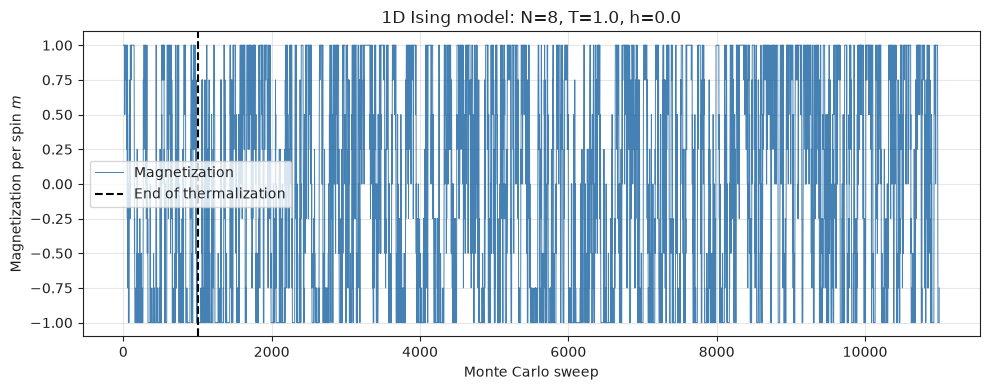

In [68]:
# Combine thermalization and measurement histories
all_m = np.concatenate([thermal_history, measurements])
sweeps = np.arange(1, len(all_m) + 1)

plt.figure(figsize=(10, 4))

plt.plot(sweeps, all_m,color=colors[0], linewidth=0.7, alpha=0.8, label="Magnetization")

# Mark the end of thermalization
plt.axvline(n_therm, linestyle="--", color="black", label="End of thermalization")

plt.xlabel("Monte Carlo sweep")
plt.ylabel("Magnetization per spin $m$")
plt.title(f"1D Ising model: N={N}, T={T}, h={h}")
plt.ylim(-1.1, 1.1)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

# plt.savefig("ising_magnetization_trace.png", dpi=200)
plt.show()


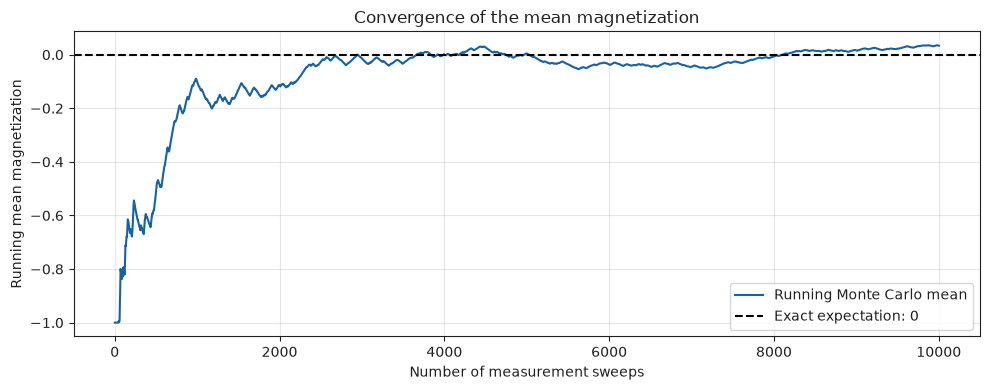

In [69]:

# Running mean after thermalization
running_mean = np.cumsum(measurements) / np.arange(1, M + 1)

plt.figure(figsize=(10, 4))

plt.plot(np.arange(1, M + 1), running_mean,color=colors[0], label="Running Monte Carlo mean")

# Theoretical value at h = 0
plt.axhline(0, linestyle="--", color="black", label="Exact expectation: 0")

plt.xlabel("Number of measurement sweeps")
plt.ylabel("Running mean magnetization")
plt.title("Convergence of the mean magnetization")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

# plt.savefig("ising_magnetization_convergence.png", dpi=200)
plt.show()


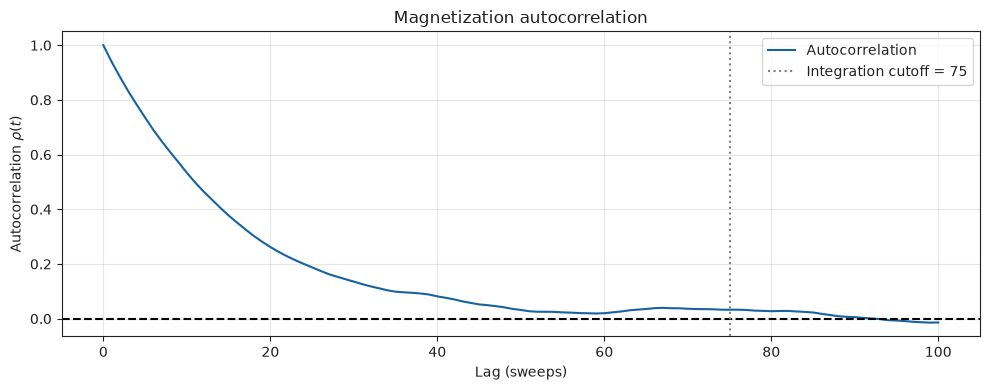

In [70]:

plt.figure(figsize=(10, 4))

plt.plot(lags, ac_values,color=colors[0], label="Autocorrelation")

plt.axhline(0, linestyle="--", color="black")
plt.axvline(cutoff, linestyle=":", color="gray",
            label=f"Integration cutoff = {cutoff}")

plt.xlabel("Lag (sweeps)")
plt.ylabel("Autocorrelation $\\rho(t)$")
plt.title("Magnetization autocorrelation")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

# plt.savefig("ising_autocorrelation.png", dpi=200)
plt.show()


# Task 3
### 3.1: dependency of $\langle m \rangle$ on external field $h$ for fixed N

In [71]:

# ============================================================
# Blocking analysis: independent error estimate
# ============================================================

def blocking_error(measurements, block_size):
    """Estimate the SEM using means of consecutive blocks."""
    m = np.asarray(measurements)

    n_blocks = len(m) // block_size

    if n_blocks < 2:
        raise ValueError("Need at least two blocks.")

    blocks = m[:n_blocks * block_size].reshape(
        n_blocks, block_size
    )

    block_means = np.mean(blocks, axis=1)

    return np.std(block_means, ddof=1) / np.sqrt(n_blocks)


block_sizes = [10, 20, 50, 100, 200, 250, 500]

print("Block size | Number of blocks | Estimated SEM")
print("-" * 50)

errors = []

for b in block_sizes:
    error = blocking_error(measurements, b)
    errors.append(error)

    print(f"{b:10d} | {M // b:16d} | {error:.6f}")

print(f"\nAutocorrelation SEM: {sem_corrected:.6f}")


Block size | Number of blocks | Estimated SEM
--------------------------------------------------
        10 |             1000 | 0.024554
        20 |              500 | 0.031943
        50 |              200 | 0.037890
       100 |              100 | 0.044325
       200 |               50 | 0.050136
       250 |               40 | 0.049568
       500 |               20 | 0.056621

Autocorrelation SEM: 0.047473


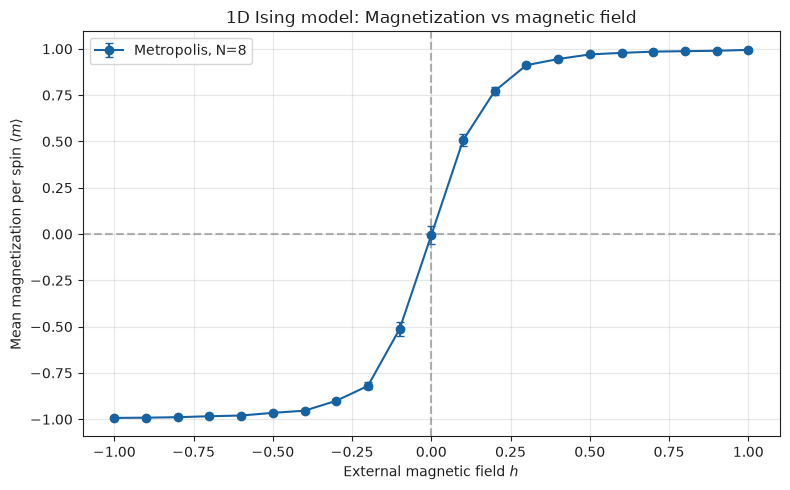

In [72]:

# Task 3a: Magnetization vs magnetic field h

N_fixed = 8
h_values = np.linspace(-1, 1, 21)

mean_vs_h = []
error_vs_h = []

rng_h = np.random.default_rng(seed=123)

for h_val in h_values:
    mean, meas, _ = run_simulation(
        N=N_fixed,
        T=1.0,
        n_therm=1000,
        n_meas=10000,
        rng=rng_h,
        J=1.0,
        h=h_val
    )

    mean_vs_h.append(mean)
    error_vs_h.append(blocking_error(meas, block_size=200))

plt.figure(figsize=(8, 5))

plt.errorbar(
    h_values, mean_vs_h, yerr=error_vs_h,
    fmt="o-", capsize=3,
    label=f"Metropolis, N={N_fixed}"
)

plt.axhline(0, color="gray", linestyle="--", alpha=0.6)
plt.axvline(0, color="gray", linestyle="--", alpha=0.6)

plt.xlabel("External magnetic field $h$")
plt.ylabel("Mean magnetization per spin $\\langle m \\rangle$")
plt.title("1D Ising model: Magnetization vs magnetic field")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


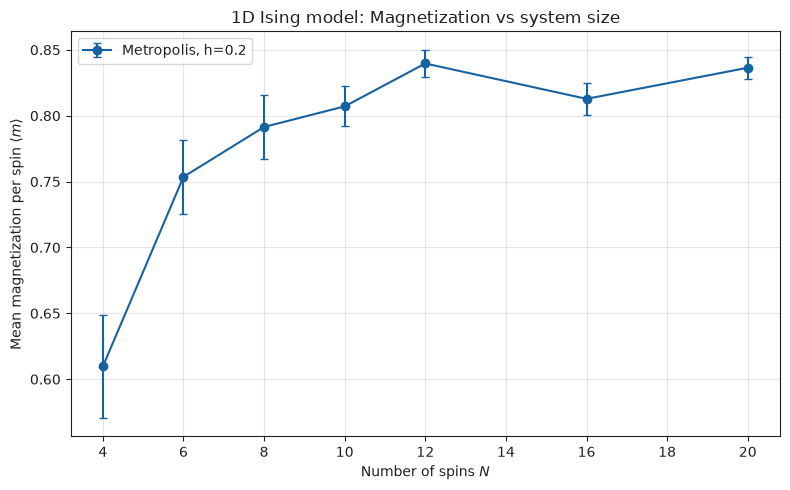

In [77]:

# Task 3b: Magnetization vs system size N

N_values = [4, 6, 8, 10, 12, 16, 20]
h_fixed = 0.2

mean_vs_N = []
error_vs_N = []

rng_N = np.random.default_rng(seed=456)

for N_val in N_values:
    mean, meas, _ = run_simulation(
        N=N_val,
        T=1.0,
        n_therm=1000,
        n_meas=10000,
        rng=rng_N,
        J=1.0,
        h=h_fixed
    )

    mean_vs_N.append(mean)
    error_vs_N.append(blocking_error(meas, block_size=200))

plt.figure(figsize=(8, 5))

plt.errorbar(
    N_values, mean_vs_N, yerr=error_vs_N,
    fmt="o-", capsize=3,
    label=f"Metropolis, h={h_fixed}"
)

plt.xlabel("Number of spins $N$")
plt.ylabel("Mean magnetization per spin $\\langle m \\rangle$")
plt.title("1D Ising model: Magnetization vs system size")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


The relevant dimensionless parameters of the 1D Ising model are \(J/T\) and \(h/T\), since \(k_B=1\). These quantify the relative influence of nearest-neighbour interactions and the external magnetic field compared to thermal fluctuations.

For fixed \(N=8\), the mean magnetization increases smoothly from approximately \(-1\) to \(+1\) as the external magnetic field increases from \(h=-1\) to \(h=1\). At \(h=0\), the magnetization vanishes within statistical uncertainties, consistent with the global spin-flip symmetry of the Hamiltonian.

For fixed \(h=0.2\), the magnetization increases with the system size \(N\) and appears to approach a constant value. Small deviations from a smooth trend can be attributed to statistical fluctuations in the Monte Carlo estimates. This behaviour can be investigated further by comparing the results with the analytical finite-size and thermodynamic-limit solutions.

# Task 4 

In [80]:
def partition_function(N, J, T, h):
    # Calculate lambda_plus and lambda_minus
    cosh_term = np.cosh(h / T)
    sqrt_term = np.sqrt(np.sinh(h / T)**2 + np.exp(-4 * J / T))

    lambda_plus = np.exp(J / T) * (cosh_term + sqrt_term)
    lambda_minus = np.exp(J / T) * (cosh_term - sqrt_term)

    return lambda_plus**N + lambda_minus**N

def exact_magnetization(N, J, T, h, eps=1e-5):
    """Exact finite-N magnetization using numerical differentiation."""

    log_Z_plus = np.log(partition_function(N, J, T, h + eps))
    log_Z_minus = np.log(partition_function(N, J, T, h - eps))

    derivative = (log_Z_plus - log_Z_minus) / (2 * eps)

    return (T / N) * derivative

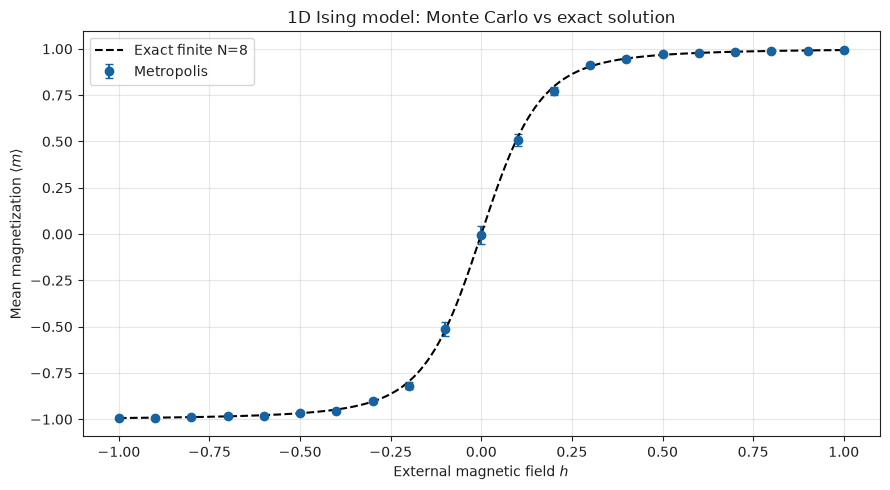

In [81]:
# Exact finite-N curve
h_dense = np.linspace(-1, 1, 400)

m_exact_h = [
    exact_magnetization(N_fixed, J, T, field)
    for field in h_dense
]

plt.figure(figsize=(9, 5))

plt.errorbar(
    h_values, mean_vs_h, yerr=error_vs_h,
    fmt="o", capsize=3, label="Metropolis"
)

plt.plot(
    h_dense, m_exact_h,
    linestyle="--", color="black",
    label=f"Exact finite N={N_fixed}"
)

plt.xlabel("External magnetic field $h$")
plt.ylabel("Mean magnetization $\\langle m\\rangle$")
plt.title("1D Ising model: Monte Carlo vs exact solution")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

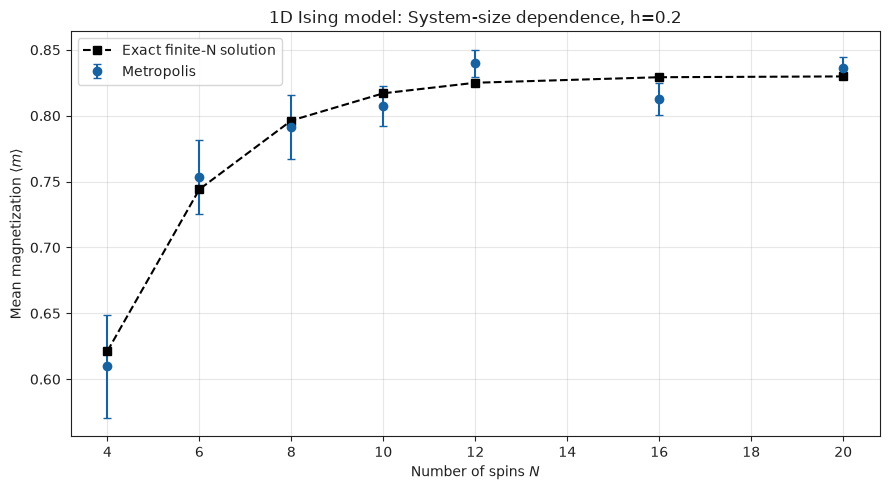

In [82]:
# Exact finite-N magnetization for each N
m_exact_N = [
    exact_magnetization(n, J, T, h_fixed)
    for n in N_values
]

plt.figure(figsize=(9, 5))

plt.errorbar(
    N_values, mean_vs_N, yerr=error_vs_N,
    fmt="o", capsize=3, label="Metropolis"
)

plt.plot(
    N_values, m_exact_N,
    "s--", color="black",
    label="Exact finite-N solution"
)

plt.xlabel("Number of spins $N$")
plt.ylabel("Mean magnetization $\\langle m\\rangle$")
plt.title(f"1D Ising model: System-size dependence, h={h_fixed}")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

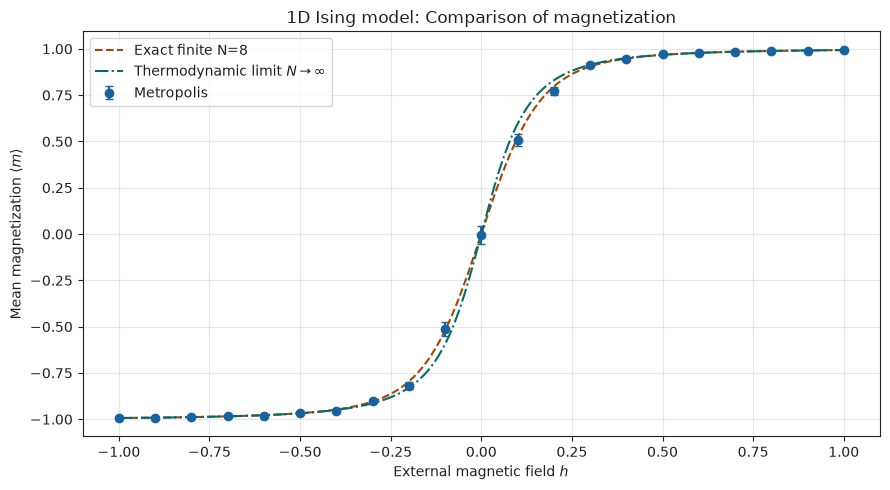

In [83]:
def magnetization_infinite(J, T, h):
    """Exact magnetization in the thermodynamic limit N -> infinity."""
    numerator = np.sinh(h / T)
    denominator = np.sqrt(
        np.sinh(h / T)**2 + np.exp(-4 * J / T)
    )
    return numerator / denominator

h_dense = np.linspace(-1, 1, 400)

m_exact_h = [
    exact_magnetization(N_fixed, J, T, h_val)
    for h_val in h_dense
]

m_infinite_h = magnetization_infinite(J, T, h_dense)

plt.figure(figsize=(9, 5))

plt.errorbar(
    h_values, mean_vs_h, yerr=error_vs_h,
    fmt="o", capsize=3, label="Metropolis"
)

plt.plot(
    h_dense, m_exact_h,
    "--", label=f"Exact finite N={N_fixed}"
)

plt.plot(
    h_dense, m_infinite_h,
    "-.", label=r"Thermodynamic limit $N\to\infty$"
)

plt.xlabel("External magnetic field $h$")
plt.ylabel(r"Mean magnetization $\langle m\rangle$")
plt.title("1D Ising model: Comparison of magnetization")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

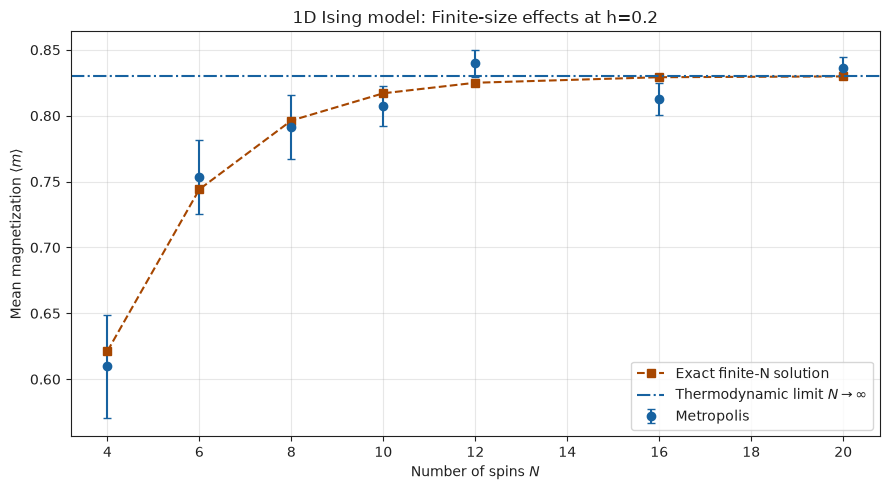

In [84]:
m_infinite = magnetization_infinite(J, T, h_fixed)

plt.figure(figsize=(9, 5))

plt.errorbar(
    N_values, mean_vs_N, yerr=error_vs_N,
    fmt="o", capsize=3, label="Metropolis"
)

plt.plot(
    N_values, m_exact_N,
    "s--", label="Exact finite-N solution"
)

plt.axhline(
    m_infinite,
    linestyle="-.",
    label=r"Thermodynamic limit $N\to\infty$"
)

plt.xlabel("Number of spins $N$")
plt.ylabel(r"Mean magnetization $\langle m\rangle$")
plt.title(f"1D Ising model: Finite-size effects at h={h_fixed}")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()